In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn

print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Pandas version: 3.1.1
NumPy version: 2.5.4
Scikit-learn version: 1.9.1


In [10]:
from sklearn.datasets import fetch_openml

housing = fetch_openml(
    name="house_prices",
    version=1,
    as_frame=True
)

df = housing.frame.copy()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [13]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   ---------------------------------------- 0/2 [et-xmlfile]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ----------------

In [15]:
df.to_excel(
    "Ames_Housing_Raw.xlsx",
    index=False
)

In [17]:
import os

print(os.path.abspath("Ames_Housing_Raw.xlsx"))

C:\Users\gnkum\PycharmProjects\House_Price_Prediction\notebooks\Ames_Housing_Raw.xlsx


In [16]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Improved Model for Streamlit Deployment.


In [52]:
# Select the features our application will collect

selected_features = [
    "OverallQual",
    "YearBuilt",
    "GrLivArea",
    "1stFlrSF",
    "TotalBsmtSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "GarageCars",
    "GarageArea",
    "LotArea",
    "YearRemodAdd"
]

X_model = df[selected_features].copy()
y_model = df["SalePrice"].copy()

print("Selected features:", len(selected_features))
print("Features shape:", X_model.shape)
print("Target shape:", y_model.shape)

Selected features: 12
Features shape: (1460, 12)
Target shape: (1460,)


In [53]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train_new.shape)
print("Testing data:", X_test_new.shape)

Training data: (1168, 12)
Testing data: (292, 12)


In [54]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor

new_rf_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

new_rf_model.fit(X_train_new, y_train_new)

print("New Random Forest model trained successfully!")

New Random Forest model trained successfully!


In [55]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

new_predictions = new_rf_model.predict(X_test_new)

new_mae = mean_absolute_error(
    y_test_new, new_predictions
)

new_rmse = np.sqrt(
    mean_squared_error(y_test_new, new_predictions)
)

new_r2 = r2_score(
    y_test_new, new_predictions
)

print("NEW MODEL PERFORMANCE")
print("---------------------")
print("MAE:", round(new_mae, 2))
print("RMSE:", round(new_rmse, 2))
print("R-squared:", round(new_r2, 4))

NEW MODEL PERFORMANCE
---------------------
MAE: 18670.58
RMSE: 30292.66
R-squared: 0.8804


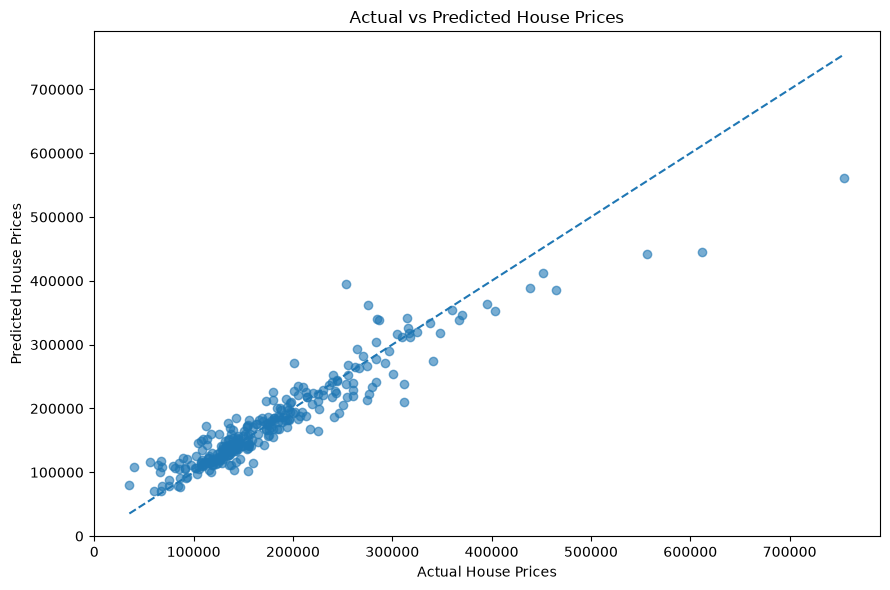

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test_new,
    new_predictions,
    alpha=0.6
)

plt.plot(
    [y_test_new.min(), y_test_new.max()],
    [y_test_new.min(), y_test_new.max()],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.tight_layout()
plt.show()

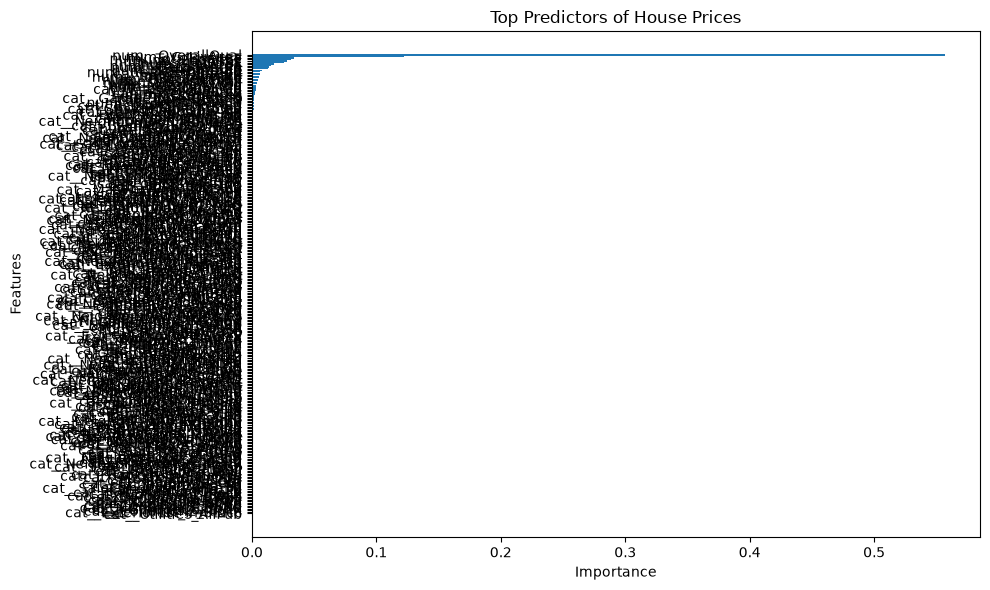

In [58]:
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top Predictors of House Prices")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [59]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

app_artifacts = {
    "model": new_rf_model,
    "features": selected_features,
    "mae": new_mae,
    "rmse": new_rmse,
    "r2": new_r2,
    "feature_importance": feature_importance,
    "actual_prices": y_test_new.to_numpy(),
    "predicted_prices": new_predictions
}

joblib.dump(
    app_artifacts,
    model_dir / "house_price_app_artifacts.joblib"
)

print("New model and dashboard information saved!")

New model and dashboard information saved!


In [61]:
from pathlib import Path

print("Current notebook location:")
print(Path.cwd())

Current notebook location:
C:\Users\gnkum\PycharmProjects\House_Price_Prediction\notebooks


In [62]:
from pathlib import Path

file_path = Path("models/house_price_app_artifacts.joblib")

print("File exists:", file_path.exists())
print("Expected location:", file_path.resolve())

File exists: True
Expected location: C:\Users\gnkum\PycharmProjects\House_Price_Prediction\notebooks\models\house_price_app_artifacts.joblib


In [63]:
from pathlib import Path
import shutil

source = Path("models/house_price_app_artifacts.joblib")

destination_folder = Path.cwd().parent / "models"
destination_folder.mkdir(exist_ok=True)

destination = destination_folder / "house_price_app_artifacts.joblib"

shutil.copy2(source, destination)

print("Model copied successfully!")
print("New location:", destination.resolve())

Model copied successfully!
New location: C:\Users\gnkum\PycharmProjects\House_Price_Prediction\models\house_price_app_artifacts.joblib
